# 2026-10-20: qubit calibration, hot-wire calibration, TWPA gain and noise

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

kB = 1.380649e-23
h = 6.62607015e-34
e = 1.602176634e-19

## 1. Qubit calibration

**Measurement**: VNA S21 around the qubit. The qubit line saturates as the power rises.

**Result**: the saturation, fitted with a 2- and 3-level model, gives the power at the qubit and so the gain from the
qubit plane to the VNA/SA, $G = 53.5$ dB (TWPA off), used below.

![qubit power sweep](261020-qubit-power-sweep.png)

## 2. Hot-wire calibration

**Measurement**: noise power on the SA at 5.576 GHz with the hot-wire bias sweeped

**Result**: the hot-wire noise at the qubit plane vs bias, $T_N^\mathrm{HE}(V)$, from a fit:

$$T_\mathrm{sys}(V) = \frac{P(V)}{k_B\,B_\mathrm{ENBW}\,G} = T_N^\mathrm{HE}(V) + T_\mathrm{add}$$

- $T_N^\mathrm{HE}$: hot-wire noise at the qubit plane
- $T_\mathrm{add}$: noise added by the chain after the qubit plane

**Model** (Bergeal *et al.*, APL 100, 203507 (2012)):

1. wire voltage: $V_w = k_V\,(V - V_0)$
2. wire electron temperature: $T^\mathrm{eff} = \frac{T_0}{2}\big[1 + (\nu + \frac1\nu)\arctan\nu\big]$, $\nu = \frac{\sqrt3}{2\pi}\frac{eV_w}{k_BT_0}$
3. at the qubit plane: $T_N^\mathrm{HE} = \eta\,\frac{hf}{2k_B}\coth\frac{hf}{2k_BT^\mathrm{eff}} + (1 - \eta)\,\frac{hf}{2k_B}$

Fit parameters: $k_V$ (bias divider), $V_0$ (offset), $\eta$ (wire → qubit plane transmission), $T_\mathrm{add}$.

101 points at 5.576 GHz
k_V = 7.608 mV/V, V0 = 0.0091 mV, eta = 0.7923 (1.01 dB), T_add = 7.330 K


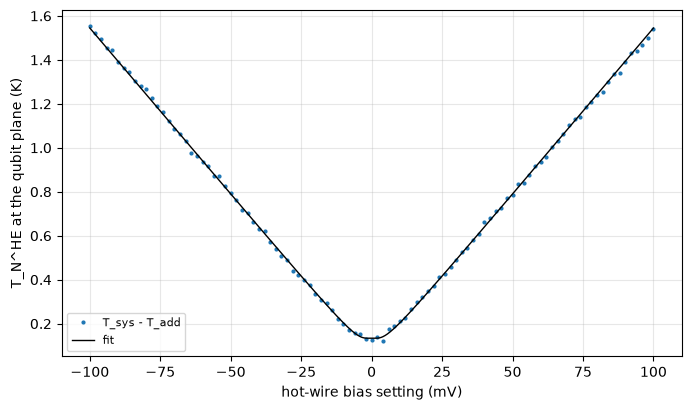

In [2]:
YF_FILE = "y_factor_0_1V.json"
G_DB = 53.72               # qubit plane -> SA/VNA reading, TWPA off
ENBW_HZ = 113.2e3         # RBW 100 kHz

with open(YF_FILE) as fh:
    yf = json.load(fh)
V = np.array(yf["bias_v"])
T_sys_yf = np.array(yf["power_w"]) / (kB * ENBW_HZ * 10 ** (G_DB / 10))
T0, f_cal = yf["fridge_temperature_k"], yf["frequency_hz"]
T_half_cal = h * f_cal / (2 * kB)     # hf/2k_B


def T_eff(Vw, T0):
    # wire electron temperature at the voltage Vw across it
    nu = np.maximum(np.sqrt(3) / (2 * np.pi) * e * np.abs(Vw) / (kB * T0), 1e-9)
    return T0 / 2 * (1 + (nu + 1 / nu) * np.arctan(nu))


def TN_HE(V, f, kV_mV, V0_mV, eta, T0):
    # hot-wire noise at the qubit plane for the bias setting V, at frequency f
    T_h = h * f / (2 * kB)
    Te = T_eff(kV_mV * 1e-3 * (V - V0_mV * 1e-3), T0)
    return eta * T_h / np.tanh(T_h / Te) + (1 - eta) * T_h


def residuals(p):
    kV_mV, V0_mV, eta, T_add = p
    return T_sys_yf - T_add - TN_HE(V, f_cal, kV_mV, V0_mV, eta, T0)


sol = least_squares(residuals, [7.0, 0.0, 0.9, T_sys_yf[np.argmin(np.abs(V))] - T_half_cal])
kV_mV, V0_mV, eta, T_add_cal = sol.x
print(f"{len(V)} points at {f_cal / 1e9:g} GHz")
print(f"k_V = {kV_mV:.3f} mV/V, V0 = {V0_mV:.4f} mV, eta = {eta:.4f} ({-10 * np.log10(eta):.2f} dB), "
      f"T_add = {T_add_cal:.3f} K")

Vm = np.linspace(V.min(), V.max(), 1001)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(V * 1e3, T_sys_yf - T_add_cal, ".", ms=4, label="T_sys - T_add")
ax.plot(Vm * 1e3, TN_HE(Vm, f_cal, kV_mV, V0_mV, eta, T0), "k", lw=1, label="fit")
ax.set(xlabel="hot-wire bias setting (mV)", ylabel="T_N^HE at the qubit plane (K)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.show()

## 3. TWPA gain and noise

- **TWPA VNA gain**: VNA S21 with the pump off and on -> the TWPA gain.
- **TWPA noise spectrum**: SA spectra of frequency band same as VNA with hot wire on/off × pump on/off -> the noise power $P$ in each state.

**Analysis** (at every frequency $f$)

1. TWPA gain: $G_\mathrm{TWPA} = |S_{21,\mathrm{on}} / S_{21,\mathrm{off}}|^2$.
2. As in section 2, the SA reads $P = a\,[T_N^\mathrm{HE} + T_\mathrm{add}]$, but now $a = k_B B_\mathrm{ENBW} G_\mathrm{chain}$
   (W/K, qubit plane → SA) is not taken from $G$ = 53.5 dB, which holds only at 5.576 GHz: it is measured at every $f$.
   With the pump off, the two hot-wire states share $a_\mathrm{off}$ and $T_\mathrm{add}$, so their difference leaves
   $$a_\mathrm{off} = \frac{P_\mathrm{off}(0.1\,\mathrm{V}) - P_\mathrm{off}(0\,\mathrm{V})}{T_N^\mathrm{HE}(0.1\,\mathrm{V}) - T_N^\mathrm{HE}(0)}$$
   with $T_N^\mathrm{HE}$ from the fit of section 2.
3. The pump changes only the TWPA: $a_\mathrm{on} = a_\mathrm{off}\,G_\mathrm{TWPA}$. The system noise at the qubit plane is the
   noise with the hot wire at 0 V divided by $a$:
   $$T_\mathrm{sys,off} = \frac{P_\mathrm{off}(0\,\mathrm{V})}{a_\mathrm{off}}, \qquad T_\mathrm{sys,on} = \frac{P_\mathrm{on}(0\,\mathrm{V})}{a_\mathrm{off}\,G_\mathrm{TWPA}}$$
4. TWPA added noise: the pump-on system noise minus the input's half photon and the chain after the TWPA,
   $$T_\mathrm{add}^\mathrm{TWPA} = T_\mathrm{sys,on} - \frac{hf}{2k_B} - \frac{T_\mathrm{sys,off} - hf/2k_B}{G_\mathrm{TWPA}}$$
   against $\frac12\big(1 - \frac1{G_\mathrm{TWPA}}\big)$ photons for an ideal amplifier. Photons: $k_BT/hf$.

In [3]:
VNA_FILE = "8_52ghz_6dbm_vna.json"   # TWPA VNA gain
SA_FILE = "8_52ghz_6dbm_sa.json"     # TWPA noise spectrum
BANDS_HZ = 100e6                          # band for the table


def twpa(vna_file, sa_file):
    with open(vna_file) as fh:
        v = json.load(fh)
    with open(sa_file) as fh:
        d = json.load(fh)
    f = np.array(v["frequency_hz"])
    assert np.allclose(d["frequency_hz"], f) and np.isclose(d["pump_frequency_hz"], v["pump_frequency_hz"])
    s_off = np.array(v["s21_off_real"]) + 1j * np.array(v["s21_off_imag"])
    s_on = np.array(v["s21_on_real"]) + 1j * np.array(v["s21_on_imag"])
    G = np.abs(s_on / s_off) ** 2
    P = {(pump, wire): np.array(d["power_w"][f"pump_{pump}_wire_{wire}"]) for pump in ("off", "on") for wire in ("0", "on")}
    T_h = h * f / (2 * kB)
    dTN = TN_HE(d["hot_wire_on_v"], f, kV_mV, V0_mV, eta, d["fridge_temperature_k"]) - T_h
    a_off = (P["off", "on"] - P["off", "0"]) / dTN
    T_off = P["off", "0"] / a_off
    T_on = P["on", "0"] / (a_off * G)
    return dict(f=f, P=P, G=G, n=2 * T_h, T_off=T_off, T_on=T_on, T_twpa=T_on - T_h - (T_off - T_h) / G,
                s_off=s_off, s_on=s_on)


r = twpa(VNA_FILE, SA_FILE)
f = r["f"]
edges = np.arange(f[0], f[-1] + 1, BANDS_HZ)
print(f"{'band (GHz)':>10} {'gain (dB)':>9} {'T_sys off (K)':>13} {'T_sys on (K)':>12} {'on (ph)':>8} {'TWPA add (ph)':>13} "
      f"{'ideal (ph)':>10}")
for lo, hi in zip(edges[:-1], edges[1:]):
    m = (f >= lo) & (f < hi)
    print(f"{lo / 1e9:4.1f}-{hi / 1e9:3.1f}   {10 * np.log10(r['G'][m]).mean():9.2f} {r['T_off'][m].mean():13.2f} "
          f"{r['T_on'][m].mean():12.2f} {(r['T_on'] / r['n'])[m].mean():8.2f} {(r['T_twpa'] / r['n'])[m].mean():13.2f} "
          f"{(0.5 * (1 - 1 / r['G']))[m].mean():10.2f}")

band (GHz) gain (dB) T_sys off (K) T_sys on (K)  on (ph) TWPA add (ph) ideal (ph)
 5.5-5.6       10.38          7.16         1.20     4.52          1.49       0.45
 5.6-5.7       11.48          8.05         1.17     4.33          1.68       0.46
 5.7-5.8       11.18          6.85         1.10     4.00          1.57       0.46
 5.8-5.9       11.41          7.46         1.16     4.12          1.68       0.46
 5.9-6.0       11.74          7.73         1.11     3.88          1.56       0.47
 6.0-6.1       12.32          8.03         1.10     3.80          1.67       0.47
 6.1-6.2       12.61          8.45         1.11     3.76          1.63       0.47
 6.2-6.3       12.47          7.29         1.07     3.57          1.64       0.47
 6.3-6.4       12.61          7.44         1.04     3.43          1.57       0.47
 6.4-6.5       12.81          7.81         1.11     3.57          1.65       0.47
 6.5-6.6       13.27          8.32         1.12     3.57          1.72       0.47
 6.6-6.7       1

|S21| with the pump off and on, spectra, $T_\mathrm{sys}$ with the pump off and on, TWPA added noise.

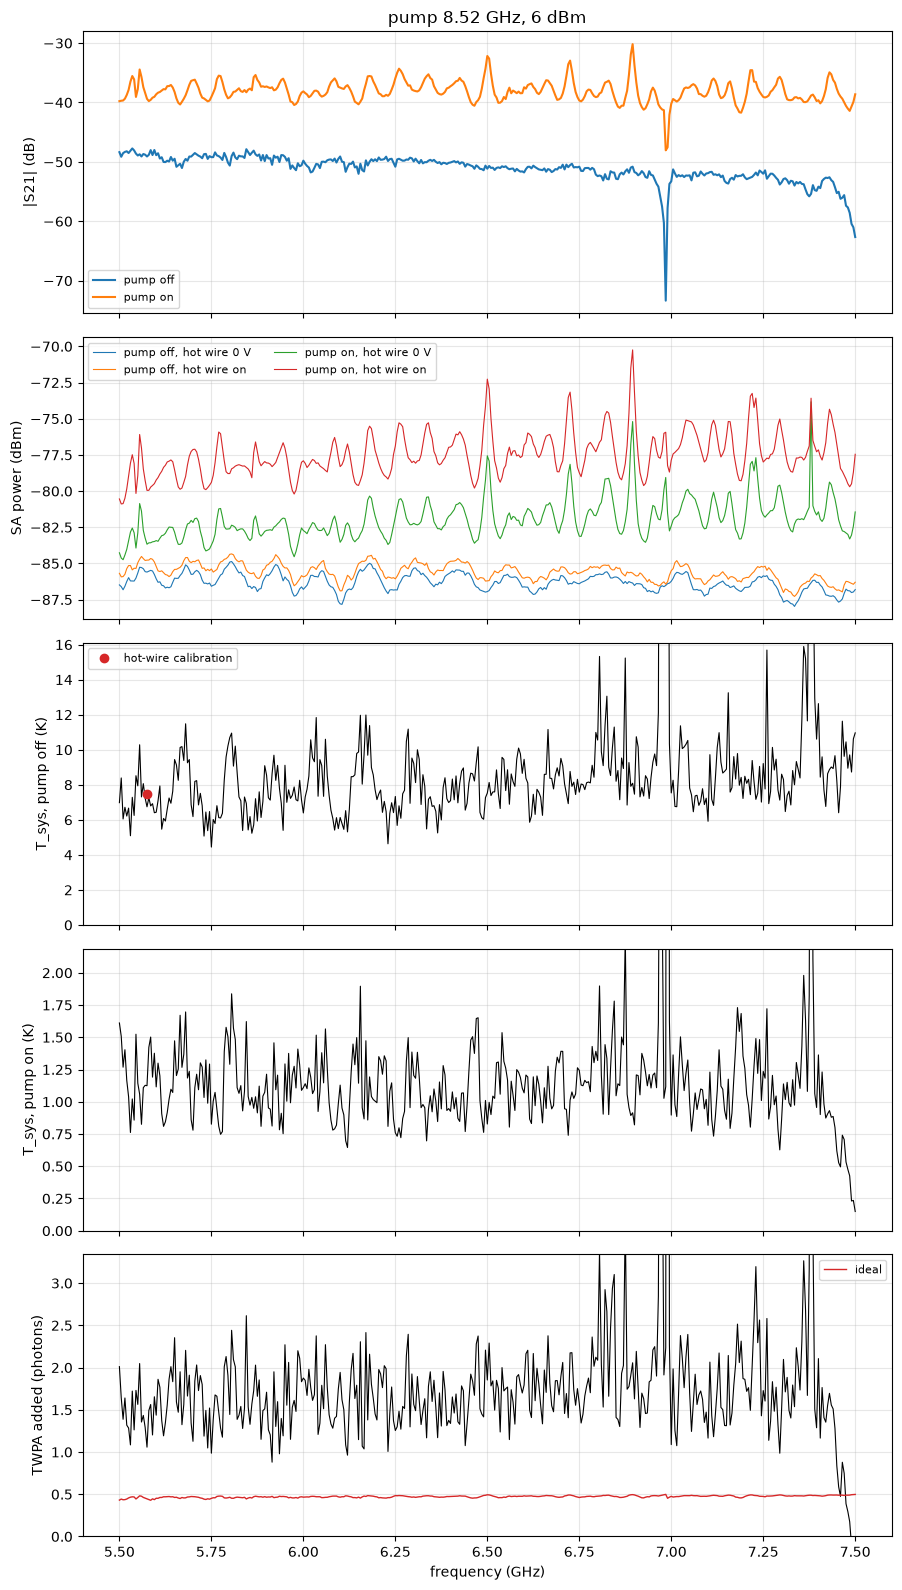

In [4]:
fx = f / 1e9
fig, ax = plt.subplots(5, 1, figsize=(9, 16), sharex=True)
ax[0].plot(fx, 20 * np.log10(np.abs(r["s_off"])), label="pump off")
ax[0].plot(fx, 20 * np.log10(np.abs(r["s_on"])), label="pump on")
ax[0].set(ylabel="|S21| (dB)", title="pump 8.52 GHz, 6 dBm")
ax[0].legend(fontsize=8)
for (pump, wire), c in zip(r["P"], ("C0", "C1", "C2", "C3")):
    ax[1].plot(fx, 10 * np.log10(r["P"][pump, wire] / 1e-3), c, lw=0.8,
               label=f"pump {pump}, hot wire {'0 V' if wire == '0' else 'on'}")
ax[1].set(ylabel="SA power (dBm)")
ax[1].legend(fontsize=8, ncol=2)
for a_, y, label in ((ax[2], r["T_off"], "T_sys, pump off (K)"), (ax[3], r["T_on"], "T_sys, pump on (K)"),
                     (ax[4], r["T_twpa"] / r["n"], "TWPA added (photons)")):
    a_.plot(fx, y, "k", lw=0.8)
    a_.set(ylabel=label, ylim=(0, 2 * np.median(y)))
ax[2].plot(f_cal / 1e9, T_add_cal + T_half_cal, "o", color="C3", label="hot-wire calibration")
ax[2].legend(fontsize=8)
ax[4].plot(fx, 0.5 * (1 - 1 / r["G"]), "C3", lw=1, label="ideal")
ax[4].legend(fontsize=8)
ax[4].set(xlabel="frequency (GHz)")
for a_ in ax:
    a_.grid(alpha=0.3)
fig.tight_layout()
plt.show()